
# DBSCAN Clustering - From Zero to Hero

**DBSCAN** = **D**ensity-**B**ased **S**patial **C**lustering of **A**pplications with **N**oise.

It is an **unsupervised** clustering algorithm: you give it points with **no labels**, and it
discovers groups from how **densely packed** the points are. It also has a superpower that
K-Means does not have - it can say *"this point does not belong to any group"* and label it
**noise / outlier**.

### The concert example

Imagine a concert crowd seen from above:

- People standing shoulder to shoulder form **dense regions** -> these become clusters.
- A single person standing far away from everyone else is **not part of any crowd** -> noise.

DBSCAN does not need you to say "there are 3 groups". It finds the groups from the density,
and it tells you which points are just lonely.

### What you will learn

1. What DBSCAN is and how it differs from K-Means.
2. The two knobs: `eps` and `min_samples`.
3. Core points, border points and noise points.
4. How the algorithm actually **grows** a cluster.
5. How to choose `eps` with the **k-distance graph**.
6. How to calculate DBSCAN with real code - **from scratch** and with **scikit-learn**.
7. An **interactive playground** to tune the knobs and see the effect instantly.
8. Why DBSCAN handles curved shapes that break K-Means.

> **Note:** The dataset is synthetic (fake) and ships as `dbscan_points.csv`. It has 278 points,
> two coordinates `x` and `y`, and a `true_group` column that was used to *generate* the data.
> DBSCAN **never reads** `true_group` - we only compare against it at the very end to check how
> well the algorithm recovered the truth.



## 1. What is DBSCAN?

### The idea in one sentence

> DBSCAN groups points that are **close together and dense**, and marks isolated points as noise.

### Why is it different from K-Means?

| | K-Means | DBSCAN |
|---|---|---|
| Number of clusters | You must choose `k` first | Found automatically |
| Cluster shape | Assumes round / spherical blobs | Any shape, as long as it is dense |
| Outliers | Every point is forced into a cluster | Points far from everything become **noise** |
| Needs scaling? | Yes | Yes (it uses distances) |

### The three kinds of points

DBSCAN classifies every point into exactly one of three types. Understanding these three words
is 90% of understanding DBSCAN:

1. **Core point** - a point that has at least `min_samples` neighbours (including itself)
   inside a circle of radius `eps`.
2. **Border point** - a point that is *not* core, but lies inside the `eps` circle of a core point.
3. **Noise point** - a point that is neither core nor border. It is alone / far from dense regions.

### A cluster, formally

A **cluster** is a maximal set of **density-connected** points:

- start from any core point,
- take all points within `eps`,
- any of those that are also core pull in *their* neighbours,
- keep expanding until no new points can be added.

Points on the edge that are reachable but not dense enough to expand are the **border** points.



## 2. The two knobs you must understand

DBSCAN has only **two** parameters, and they control everything.

### `eps` (epsilon) - the neighbourhood radius

`eps` is the radius of the circle drawn around each point. Two points are **neighbours** if the
distance between them is `<= eps`.

- **Small `eps`** -> small, tight circles -> many points fail the density test -> many small
  clusters and lots of noise.
- **Large `eps`** -> big circles -> everything is connected -> one giant cluster.

### `min_samples` - the density threshold

`min_samples` is the minimum number of points (including the point itself) that must sit inside
the `eps` circle for the point to be a **core point**.

- **Small `min_samples`** -> easy to be core -> clusters merge easily.
- **Large `min_samples`** -> hard to be core -> fewer clusters, more noise.

### The golden rule

> `eps` controls **how far** "close" is. `min_samples` controls **how many** neighbours are
> needed to call a region "dense".

In practice people often set `min_samples` to about `2 * number_of_features` (so for 2D data,
`min_samples = 4` is a common starting point) and then tune `eps` using the k-distance graph
shown later in this notebook.



## 3. How the algorithm works, step by step

Here is the whole algorithm in plain language:

```
for each point p in the dataset:
    if p was already visited: skip it

    find all points within eps of p   (its neighbours)

    if p has fewer than min_samples neighbours:
        mark p as NOISE               (for now)
    else:
        start a NEW cluster
        put p and all its neighbours in it
        for every point q added to the cluster:
            if q is a core point:
                also add all of q's neighbours to the cluster
        keep expanding until nothing new is added
```

That is it. The magic is in the **expansion**: one core point pulls in its neighbours, and any
neighbour that is itself core pulls in *its* neighbours, so a whole dense region is swallowed in
one go.

### A useful detail

A point marked as noise early can be **promoted later**. If it turns out to sit inside the `eps`
circle of a core point from some cluster, it becomes a **border point** of that cluster. This is
why the code below checks for "was noise, now reachable" while expanding.

### Pseudocode vs real code

The notebook later implements this exact loop in Python (`dbscan_from_scratch`) and then
compares it against scikit-learn's optimised version.



## 4. Setup - the tools we need

We will use:

- **NumPy** for the numerical work and the from-scratch implementation.
- **Pandas** to load and explore `dbscan_points.csv`.
- **Matplotlib** to draw every chart.
- **scikit-learn** for `DBSCAN`, `KMeans`, `NearestNeighbors` and scoring metrics.
- **ipywidgets** to make the notebook interactive (sliders you can play with).

> Keep `dbscan_points.csv` in the **same folder** as this notebook so that
> `pd.read_csv("dbscan_points.csv")` can find it.


In [1]:

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider, fixed, Play, jslink
from IPython.display import display

# Friendly, consistent chart styling.
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 11

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
import sklearn
print("scikit-learn", sklearn.__version__)


numpy        2.5.4
pandas       3.1.1
scikit-learn 1.9.1



## 5. Load the fake dataset

The file `dbscan_points.csv` has 278 rows. Each row is one point:

| Column | Meaning |
|---|---|
| `id` | A unique number for each point |
| `x` | The horizontal coordinate |
| `y` | The vertical coordinate |
| `true_group` | The group used to *generate* the point (DBSCAN ignores this) |

The data was designed to contain:

- **two round blobs** (easy, K-Means-friendly),
- **one curved arc** (non-spherical - this is where DBSCAN beats K-Means),
- **one small dense blob**,
- **18 random noise points** scattered around.


In [2]:

df = pd.read_csv("dbscan_points.csv")
df.head(10)


,id,x,y,true_group
0,1,1.722,1.184,blob_A
1,2,1.900,1.976,blob_A
2,3,0.820,1.079,blob_A
3,4,1.651,1.474,blob_A
4,5,1.593,1.259,blob_A
5,6,1.952,1.911,blob_A
6,7,1.626,2.051,blob_A
7,8,1.787,1.256,blob_A
8,9,1.748,1.216,blob_A
9,10,1.951,1.580,blob_A


In [3]:

print("shape:", df.shape)
print("\nmissing values per column:")
print(df.isna().sum())
print("\nsummary statistics:")
df.describe().round(2)


shape: (278, 4)

missing values per column:
id            0
x             0
y             0
true_group    0
dtype: int64

summary statistics:


,id,x,y
count,278.00,278.00,278.00
mean,139.50,5.58,4.96
std,80.40,2.83,2.78
min,1.00,0.14,-0.01
25%,70.25,2.88,1.93
50%,139.50,6.52,5.34
75%,208.75,8.19,7.79
max,278.00,10.39,10.00



### Look at the raw points (no labels)

This is what DBSCAN receives: just `x` and `y`. No colours, no groups.


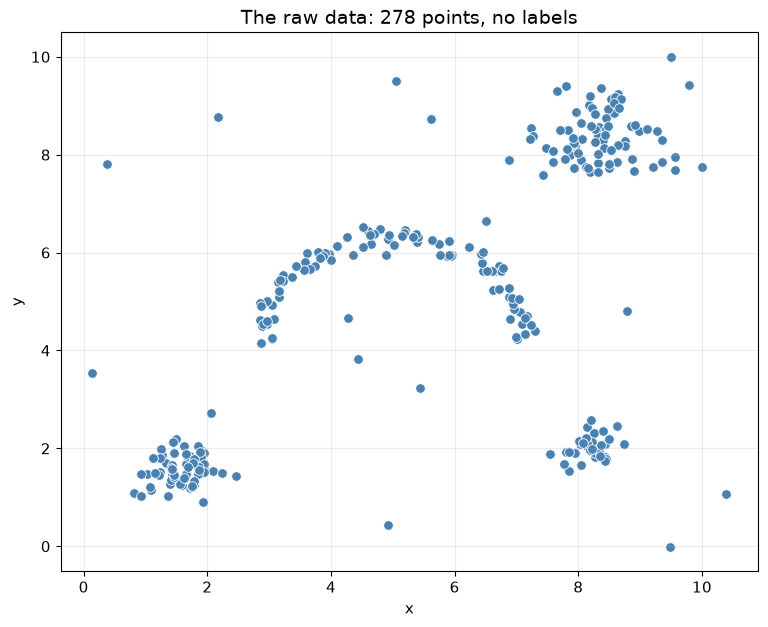

In [4]:

X = df[["x", "y"]].to_numpy()          # the only thing DBSCAN is allowed to see

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(X[:, 0], X[:, 1], s=48, c="steelblue", edgecolors="white", linewidths=0.6)
ax.set_title("The raw data: 278 points, no labels", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()



### ...and this is the truth we hid (for comparison only)

Colouring by `true_group` shows what the data generator did. DBSCAN never sees these colours -
this plot is only so that *you* can judge the result later.


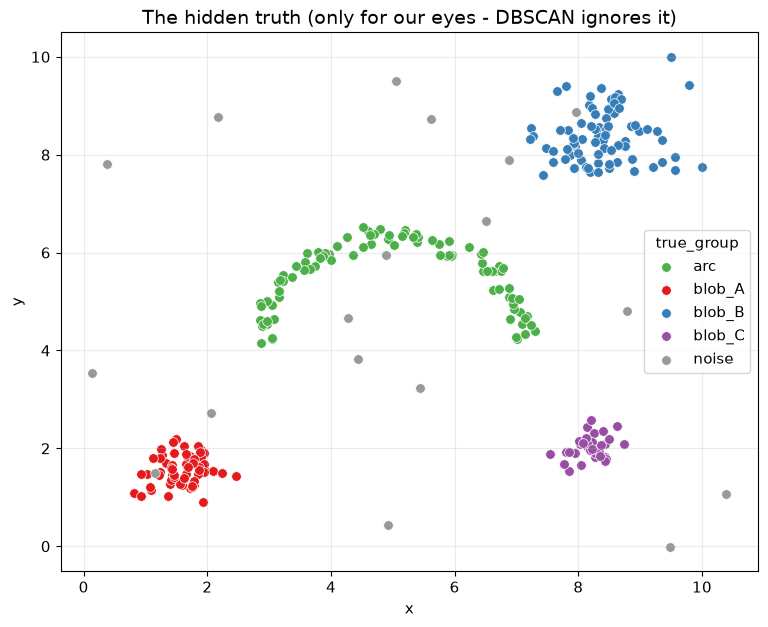

In [5]:

TRUE_COLORS = {
    "blob_A": "#e41a1c",
    "blob_B": "#377eb8",
    "arc": "#4daf4a",
    "blob_C": "#984ea3",
    "noise": "#999999",
}

fig, ax = plt.subplots(figsize=(9, 7))
for group, sub in df.groupby("true_group"):
    ax.scatter(sub["x"], sub["y"], s=48, color=TRUE_COLORS[group],
               label=group, edgecolors="white", linewidths=0.5)
ax.set_title("The hidden truth (only for our eyes - DBSCAN ignores it)", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(title="true_group")
plt.show()



## 6. Distance and neighbourhoods

DBSCAN is a **distance-based** algorithm. Before clustering, we need to know how far apart
points are and what an `eps` circle actually contains.

We compute the full **pairwise distance matrix** `D`, where `D[i, j]` is the straight-line
(Euclidean) distance between point `i` and point `j`.

Then we pick one point and draw circles of different radii around it. The number of points inside
the circle is exactly the number of neighbours DBSCAN will count.


In [6]:

def pairwise_distances(X):
    """Straight-line distance between every pair of points."""
    diff = X[:, None, :] - X[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=2))


D = pairwise_distances(X)
print("distance matrix shape:", D.shape)
print("smallest non-zero distance:", round(D[D > 0].min(), 3))
print("largest distance:          ", round(D.max(), 3))
print("average distance:          ", round(D[D > 0].mean(), 3))


distance matrix shape: (278, 278)
smallest non-zero distance: 0.017
largest distance:           12.448
average distance:           4.864


chosen point index: 58  coordinates: [1.693 1.609]


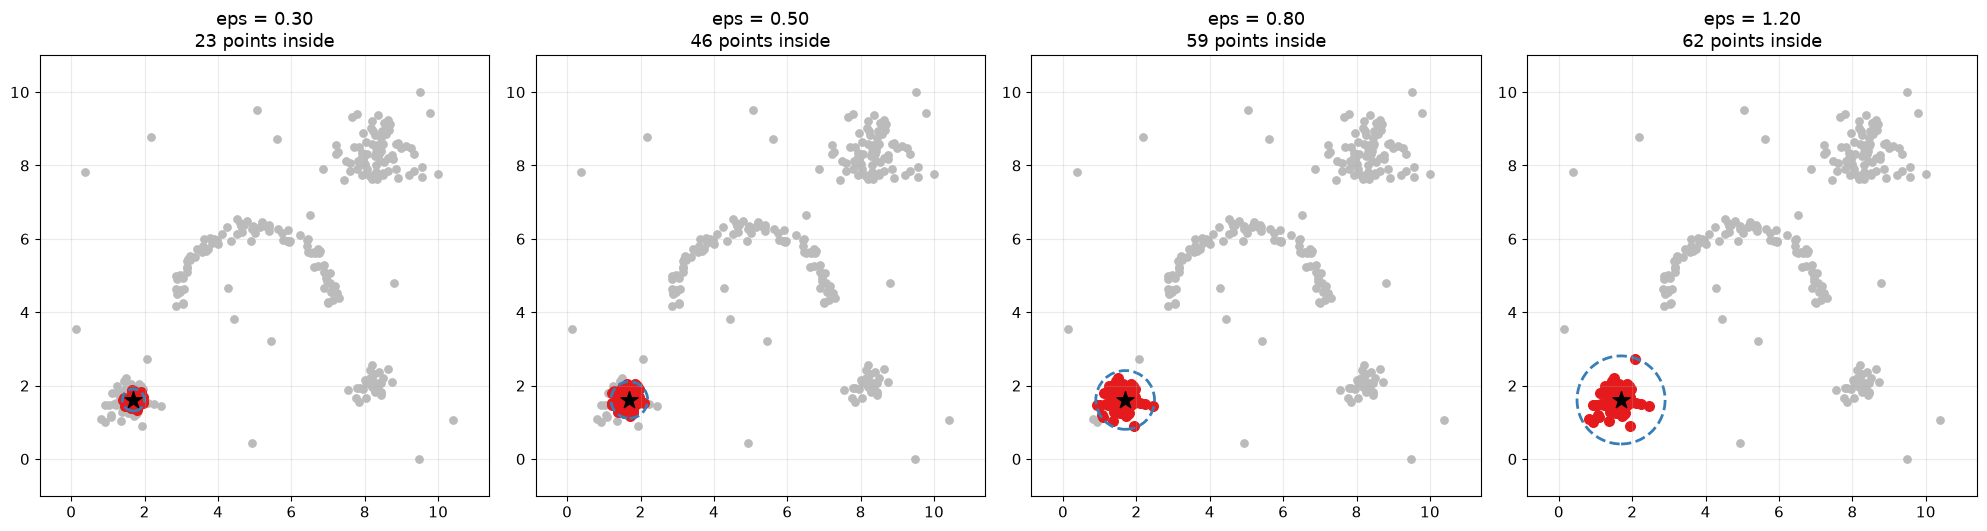

In [7]:

def plot_eps_circles(X, center_idx, eps_list):
    """Draw eps-circles of several sizes around one chosen point."""
    fig, axes = plt.subplots(1, len(eps_list), figsize=(5 * len(eps_list), 5))
    if len(eps_list) == 1:
        axes = [axes]
    cx, cy = X[center_idx]
    for ax, eps in zip(axes, eps_list):
        dist = np.linalg.norm(X - X[center_idx], axis=1)
        inside = dist <= eps
        ax.scatter(X[~inside, 0], X[~inside, 1], s=28, c="#bbbbbb")
        ax.scatter(X[inside, 0], X[inside, 1], s=48, c="#e41a1c")
        ax.scatter([cx], [cy], s=160, c="black", marker="*", zorder=5)
        ax.add_patch(Circle((cx, cy), eps, fill=False, color="#377eb8", lw=2, ls="--"))
        ax.set_title(f"eps = {eps:.2f}\n{inside.sum()} points inside")
        ax.set_xlim(X[:, 0].min() - 1, X[:, 0].max() + 1)
        ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()


# Pick the point closest to the middle of the bottom-left blob.
center_idx = int(np.argmin((X[:, 0] - 1.6) ** 2 + (X[:, 1] - 1.6) ** 2))
print("chosen point index:", center_idx, " coordinates:", X[center_idx])
plot_eps_circles(X, center_idx, [0.3, 0.5, 0.8, 1.2])



## 7. Core, border and noise - the definitions in code

Now we turn the three definitions from section 1 into a function. For every point we:

1. count how many points are within `eps` (including itself),
2. call it **core** if the count is `>= min_samples`,
3. otherwise call it **border** if at least one of its neighbours is core,
4. otherwise call it **noise**.

Try the sliders: change `eps` and `min_samples` and watch how the colours change.


In [8]:

def classify_points(X, eps, min_samples):
    """Return 'core', 'border' or 'noise' for every point (the DBSCAN definitions)."""
    neighbours = NearestNeighbors(radius=eps).fit(X).radius_neighbors(return_distance=False)
    counts = np.array([len(n) for n in neighbours])
    is_core = counts >= min_samples

    kinds = np.where(is_core, "core", "border")
    for i in range(len(X)):
        if not is_core[i] and not np.any(is_core[neighbours[i]]):
            kinds[i] = "noise"
    return kinds, counts


def plot_kinds(X, eps, min_samples):
    kinds, counts = classify_points(X, eps, min_samples)
    colors = {"core": "#e41a1c", "border": "#ff7f00", "noise": "#999999"}
    fig, ax = plt.subplots(figsize=(9, 7))
    for kind in ["noise", "border", "core"]:
        mask = kinds == kind
        ax.scatter(X[mask, 0], X[mask, 1],
                   s=70 if kind == "core" else 42,
                   c=colors[kind],
                   label=f"{kind} ({mask.sum()})",
                   edgecolors="white", linewidths=0.5)
    ax.set_title(f"eps = {eps:.2f}   |   min_samples = {min_samples}", fontsize=14)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    plt.show()


interact(plot_kinds, X=fixed(X),
         eps=FloatSlider(min=0.2, max=2.0, step=0.05, value=0.6, description="eps"),
         min_samples=IntSlider(min=2, max=15, step=1, value=5, description="min_samples"))


interactive(children=(FloatSlider(value=0.6, description='eps', max=2.0, min=0.2, step=0.05), IntSlider(value=…

<function __main__.plot_kinds(X, eps, min_samples)>


## 8. Choosing `eps` with the k-distance graph

You do not have to guess `eps` blindly. A standard trick:

1. For each point, find the distance to its **k-th nearest neighbour** (usually `k = min_samples`).
2. Sort those distances from small to large.
3. Plot them.

The curve is flat at first (points inside dense clusters are all close to their k-th neighbour)
and then suddenly shoots up (points in sparse regions / noise are far from their k-th neighbour).
The **elbow** - the point just before the sharp rise - is a good `eps` value.


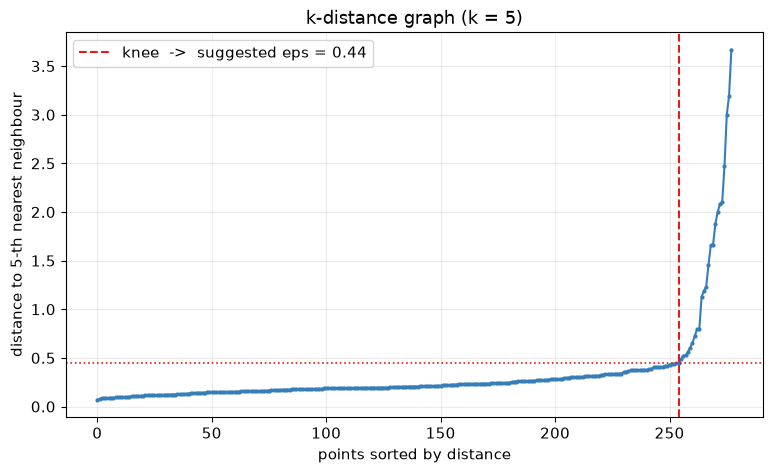

array([0.07072482, 0.07689603, 0.08556284, 0.08556284, 0.08709765,
       0.08759566, 0.08920202, 0.09047652, 0.09319335, 0.09326307,
       0.09466784, 0.09656604, 0.097     , 0.09848858, 0.09968952,
       0.10607544, 0.10607544, 0.10860018, 0.10901835, 0.10998636,
       0.11166468, 0.11475626, 0.11511733, 0.11511733, 0.11624973,
       0.11637869, 0.11759252, 0.11813975, 0.11928118, 0.12074767,
       0.12160592, 0.12257651, 0.12316655, 0.1233572 , 0.1233572 ,
       0.12404032, 0.12563439, 0.12592458, 0.12701181, 0.1332704 ,
       0.1332704 , 0.1367516 , 0.13839798, 0.14024621, 0.14090067,
       0.14090067, 0.14214429, 0.14217243, 0.14491722, 0.14558159,
       0.14698639, 0.14713939, 0.14746186, 0.14809794, 0.14921796,
       0.14921796, 0.15007332, 0.150446  , 0.150446  , 0.15079125,
       0.1517432 , 0.15259423, 0.15425952, 0.15474172, 0.15487091,
       0.15518376, 0.15518376, 0.15610894, 0.15822136, 0.1590283 ,
       0.15931416, 0.15931416, 0.15935495, 0.16207714, 0.16254

In [9]:

def k_distance_plot(X, k):
    """Plot the sorted distance to the k-th nearest neighbour and mark the knee."""
    distances, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    k_dist = np.sort(distances[:, -1])

    # Find the "knee": the point furthest below the chord joining the two ends.
    n = len(k_dist)
    x_norm = np.linspace(0, 1, n)
    y_norm = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
    chord = y_norm[0] + (y_norm[-1] - y_norm[0]) * x_norm
    elbow = int(np.argmax(chord - y_norm))
    suggested_eps = float(k_dist[elbow])

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(k_dist, marker=".", ms=4, color="#377eb8")
    ax.axhline(suggested_eps, color="#e41a1c", ls=":", lw=1.2)
    ax.axvline(elbow, color="#e41a1c", ls="--", lw=1.5,
               label=f"knee  ->  suggested eps = {suggested_eps:.2f}")
    ax.set_xlabel("points sorted by distance")
    ax.set_ylabel(f"distance to {k}-th nearest neighbour")
    ax.set_title(f"k-distance graph (k = {k})")
    ax.legend()
    plt.show()
    return k_dist


k_distance_plot(X, k=5)


In [10]:

interact(lambda k: k_distance_plot(X, k),
         k=IntSlider(min=2, max=20, step=1, value=5, description="k"))


interactive(children=(IntSlider(value=5, description='k', max=20, min=2), Output()), _dom_classes=('widget-int…

<function __main__.<lambda>(k)>


## 9. DBSCAN from scratch

Now we write the algorithm ourselves, exactly following the loop from section 3. This is the
best way to *really* understand what DBSCAN is doing.

```python
labels = -2   # not visited yet
labels = -1   # noise
labels = 0, 1, 2, ...   # cluster id
```

The function `dbscan_from_scratch(X, eps, min_samples)` returns the final labels. A second
function `dbscan_trace(...)` is a **generator** that yields a snapshot after every single step,
which we use in the next cell to animate the growth of the clusters.


In [11]:

def region_query(X, point_idx, eps):
    """All points within eps of X[point_idx] (including the point itself)."""
    dist = np.linalg.norm(X - X[point_idx], axis=1)
    return np.where(dist <= eps)[0]


def dbscan_from_scratch(X, eps, min_samples):
    """A readable, step-by-step implementation of DBSCAN.

    Returns an array of labels: -1 = noise, 0,1,2,... = cluster id.
    """
    n_points = len(X)
    labels = np.full(n_points, -2)          # -2 = not visited yet
    cluster_id = 0

    for i in range(n_points):
        if labels[i] != -2:                 # already processed
            continue

        neighbours = region_query(X, i, eps)

        if len(neighbours) < min_samples:   # not dense enough -> noise (for now)
            labels[i] = -1
            continue

        # ---- start a brand new cluster ----
        labels[i] = cluster_id
        seeds = [j for j in neighbours if j != i]

        while seeds:
            j = seeds.pop()
            if labels[j] == -1:             # noise that is reachable -> becomes border
                labels[j] = cluster_id
            if labels[j] != -2:             # already assigned
                continue
            labels[j] = cluster_id
            j_neighbours = region_query(X, j, eps)
            if len(j_neighbours) >= min_samples:   # j is core -> expand the cluster
                seeds.extend(j_neighbours)

        cluster_id += 1

    return labels


In [12]:

def dbscan_trace(X, eps, min_samples):
    """Generator: yield a snapshot after every meaningful step of DBSCAN."""
    n_points = len(X)
    labels = np.full(n_points, -2)
    cluster_id = 0
    yield {"labels": labels.copy(), "current": None, "event": "start", "cluster": cluster_id}

    for i in range(n_points):
        if labels[i] != -2:
            continue

        neighbours = region_query(X, i, eps)
        yield {"labels": labels.copy(), "current": i, "event": "visit",
               "cluster": cluster_id, "neighbours": neighbours}

        if len(neighbours) < min_samples:
            labels[i] = -1
            yield {"labels": labels.copy(), "current": i, "event": "noise", "cluster": cluster_id}
            continue

        labels[i] = cluster_id
        seeds = [j for j in neighbours if j != i]
        yield {"labels": labels.copy(), "current": i, "event": "new_cluster", "cluster": cluster_id}

        while seeds:
            j = seeds.pop()
            if labels[j] == -1:
                labels[j] = cluster_id
            if labels[j] != -2:
                continue
            labels[j] = cluster_id
            j_neighbours = region_query(X, j, eps)
            yield {"labels": labels.copy(), "current": j, "event": "assign",
                   "cluster": cluster_id, "neighbours": j_neighbours}
            if len(j_neighbours) >= min_samples:
                seeds.extend(j_neighbours)

        cluster_id += 1

    yield {"labels": labels.copy(), "current": None, "event": "done", "cluster": cluster_id}



### Watch the clusters grow, step by step

Use the slider (or press **Play**) to move through every step of the algorithm. The red ring is
the point currently being examined. Grey points are not visited yet, black crosses are noise,
and colours are clusters.

- `visit` - the algorithm looks at a new point.
- `noise` - too few neighbours, so it is marked noise.
- `new_cluster` - a core point was found, a new cluster is born.
- `assign` - a point is swallowed into the growing cluster.


In [13]:

EPS0, MIN0 = 0.6, 5
trace = list(dbscan_trace(X, EPS0, MIN0))
print("total steps:", len(trace))

step_slider = IntSlider(min=0, max=len(trace) - 1, step=1, value=0, description="step")
play = Play(min=0, max=len(trace) - 1, step=1, interval=250, description="press play")
jslink((play, "value"), (step_slider, "value"))
display(widgets.HBox([play, step_slider]))


def show_step(step):
    snap = trace[step]
    labels = snap["labels"]
    palette = plt.cm.tab10(np.linspace(0, 1, 10))

    fig, ax = plt.subplots(figsize=(9, 7))
    for idx in range(len(X)):
        if labels[idx] == -2:
            color = "#dddddd"
        elif labels[idx] == -1:
            color = "#222222"
        else:
            color = palette[labels[idx] % 10]
        ax.scatter(X[idx, 0], X[idx, 1], s=46, c=[color],
                   marker="x" if labels[idx] == -1 else "o",
                   edgecolors="white", linewidths=0.4)

    if snap["current"] is not None:
        cx, cy = X[snap["current"]]
        ax.scatter([cx], [cy], s=260, facecolors="none",
                   edgecolors="red", linewidths=2.5, label="current point")

    ax.set_title(f"step {step}/{len(trace)-1}   event: {snap['event']}   "
                 f"cluster: {snap['cluster']}", fontsize=13)
    ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
    ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ax.legend()
    plt.show()


interact(show_step, step=step_slider)


total steps: 300


interactive(children=(IntSlider(value=0, description='step', max=299), Output()), _dom_classes=('widget-intera…

<function __main__.show_step(step)>


## 10. Run our implementation and check it against scikit-learn

We now run the from-scratch version and scikit-learn's `DBSCAN` on the same data and compare.

- The **cluster ids may be numbered differently** (cluster 0 in one may be cluster 1 in the
  other), so we compare with the **Adjusted Rand Index (ARI)**, which ignores the actual ids and
  only cares about *which points are grouped together*.
- `ARI = 1.0` means the two partitions are identical up to renaming.


In [14]:

eps, min_samples = 0.6, 5

labels_scratch = dbscan_from_scratch(X, eps, min_samples)
labels_sklearn = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)


def summary(labels, name):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    print(f"{name:12s} -> clusters: {n_clusters}   noise: {n_noise}/{len(labels)}")


summary(labels_scratch, "from scratch")
summary(labels_sklearn, "scikit-learn")
print()
print("Adjusted Rand Index (scratch vs sklearn):",
      round(adjusted_rand_score(labels_scratch, labels_sklearn), 4))


from scratch -> clusters: 4   noise: 16/278
scikit-learn -> clusters: 4   noise: 16/278

Adjusted Rand Index (scratch vs sklearn): 1.0


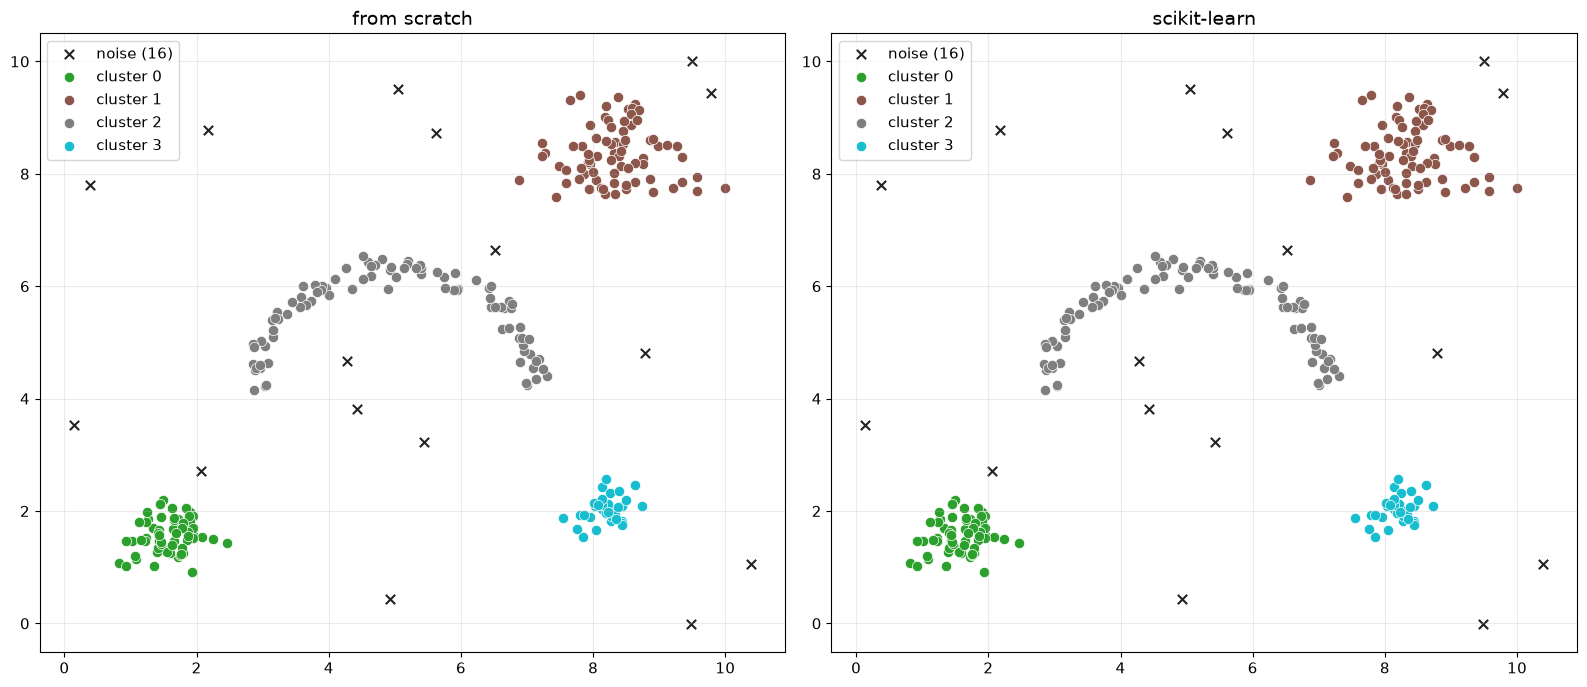

In [15]:

def plot_dbscan_clusters(X, labels, title):
    """Colour points by cluster; noise is drawn as a black cross."""
    unique = sorted(set(labels))
    palette = plt.cm.tab10(np.linspace(0, 1, max(len(unique), 1)))

    fig, ax = plt.subplots(figsize=(9, 7))
    for k, lab in enumerate(unique):
        mask = labels == lab
        if lab == -1:
            ax.scatter(X[mask, 0], X[mask, 1], s=45, c="#222222", marker="x",
                       label=f"noise ({mask.sum()})")
        else:
            ax.scatter(X[mask, 0], X[mask, 1], s=55, c=[palette[k % 10]],
                       label=f"cluster {lab} ({mask.sum()})",
                       edgecolors="white", linewidths=0.5)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    plt.show()


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, labels, title in zip(
        axes,
        [labels_scratch, labels_sklearn],
        ["from scratch", "scikit-learn"]):
    unique = sorted(set(labels))
    palette = plt.cm.tab10(np.linspace(0, 1, max(len(unique), 1)))
    for k, lab in enumerate(unique):
        mask = labels == lab
        if lab == -1:
            ax.scatter(X[mask, 0], X[mask, 1], s=45, c="#222222", marker="x",
                       label=f"noise ({mask.sum()})")
        else:
            ax.scatter(X[mask, 0], X[mask, 1], s=55, c=[palette[k % 10]],
                       label=f"cluster {lab}", edgecolors="white", linewidths=0.5)
    ax.set_title(title, fontsize=14)
    ax.legend()
plt.tight_layout()
plt.show()



### Score the result against the hidden truth

DBSCAN does not use `true_group`, but now that the run is done we can compare. The
**Adjusted Rand Index** again measures agreement (1.0 = perfect recovery, 0 = random).


In [16]:

n_clusters = len(set(labels_sklearn)) - (1 if -1 in labels_sklearn else 0)
n_noise = int((labels_sklearn == -1).sum())
print(f"clusters found : {n_clusters}")
print(f"noise points   : {n_noise} / {len(X)}")

mask = labels_sklearn != -1
if n_clusters > 1:
    print("silhouette score (cluster points only):",
          round(silhouette_score(X[mask], labels_sklearn[mask]), 3))
print("ARI vs the hidden true_group:",
      round(adjusted_rand_score(df["true_group"], labels_sklearn), 3))


clusters found : 4
noise points   : 16 / 278
silhouette score (cluster points only): 0.704
ARI vs the hidden true_group: 0.963



## 11. The interactive playground

This is the fun part. Move the two sliders and watch DBSCAN re-cluster the data **live**.

Things to try:

- **Shrink `eps`** until the big clusters shatter into many small ones.
- **Grow `eps`** until everything collapses into a single cluster.
- **Raise `min_samples`** and watch the arc lose its thin tail first.
- Find the setting that best matches the hidden truth.


In [17]:

def playground(eps, min_samples):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    plot_dbscan_clusters(X, labels, f"DBSCAN  |  eps = {eps:.2f}  |  min_samples = {min_samples}")
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"clusters: {n_clusters}   noise: {int((labels == -1).sum())}")


interact(playground,
         eps=FloatSlider(min=0.2, max=1.5, step=0.05, value=0.6,
                         description="eps", continuous_update=False),
         min_samples=IntSlider(min=2, max=15, step=1, value=5,
                               description="min_samples", continuous_update=False))


interactive(children=(FloatSlider(value=0.6, continuous_update=False, description='eps', max=1.5, min=0.2, ste…

<function __main__.playground(eps, min_samples)>


## 12. Where DBSCAN beats K-Means: curved shapes

K-Means assumes clusters are round blobs. Give it a **two-moon** dataset and it cuts the moons
in half, because it always draws a straight line between centroids. DBSCAN follows the density
and recovers the two moons perfectly.

This is the single best visual argument for density-based clustering.


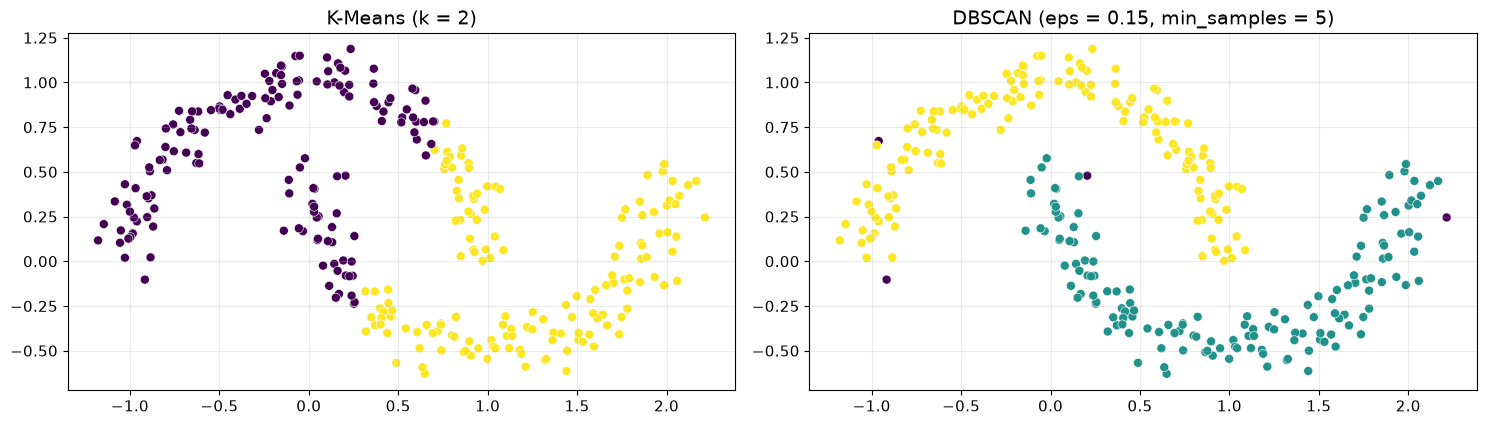

K-Means ARI vs the two moons : 0.261
DBSCAN ARI vs the two moons : 0.973


In [18]:

X_moons, y_moons = make_moons(n_samples=300, noise=0.08, random_state=42)

labels_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_moons)
labels_db = DBSCAN(eps=0.15, min_samples=5).fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in zip(axes, [labels_km, labels_db],
                             ["K-Means (k = 2)", "DBSCAN (eps = 0.15, min_samples = 5)"]):
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap="viridis",
               s=42, edgecolors="white", linewidths=0.4)
    ax.set_title(title, fontsize=14)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("K-Means ARI vs the two moons :", round(adjusted_rand_score(y_moons, labels_km), 3))
print("DBSCAN ARI vs the two moons :", round(adjusted_rand_score(y_moons, labels_db), 3))



## 13. Tuning guide - reading the symptoms

| What you see | Most likely cause | What to try |
|---|---|---|
| One giant cluster, no noise | `eps` too large **or** `min_samples` too small | decrease `eps`, increase `min_samples` |
| Everything is noise | `eps` too small **or** `min_samples` too large | increase `eps`, decrease `min_samples` |
| Many tiny clusters | `eps` too small | increase `eps` (or lower `min_samples`) |
| Clusters of very different density get merged | one global `eps` is not enough | use **OPTICS** or **HDBSCAN** |
| Clusters look wrong even after tuning | features are on different scales | **standardise** the features first |

### Practical checklist

1. **Scale your features.** DBSCAN uses distances, so a feature measured in thousands will
   dominate one measured in fractions. Use `StandardScaler` (or the data is already comparable,
   as in this notebook).
2. **Set `min_samples`** to roughly `2 * n_features` (for 2D: 4-6).
3. **Pick `eps`** from the k-distance elbow.
4. **Plot the result** and check the noise points - they should look genuinely isolated.
5. If clusters have very different densities, consider **HDBSCAN**, the hierarchical successor
   of DBSCAN.

### When not to use DBSCAN

- Clusters have very **different densities** and you cannot switch to HDBSCAN.
- The data is **very high dimensional** (distances become less meaningful - the "curse of
  dimensionality").
- You need a **soft / probabilistic** membership (then use Gaussian Mixture Models).



## 14. Summary cheat sheet

| Concept | Meaning |
|---|---|
| `eps` | Radius of the neighbourhood circle |
| `min_samples` | Minimum neighbours for a point to be **core** |
| **Core point** | Has `>= min_samples` points within `eps` |
| **Border point** | Not core, but within `eps` of a core point |
| **Noise point** | Neither core nor border |
| **Density-connected** | Linked by a chain of core points within `eps` |
| Cluster | A maximal set of density-connected points |
| k-distance graph | Tool to choose `eps` (look for the elbow) |

### The algorithm in 5 lines

1. Visit every point.
2. Count its neighbours within `eps`.
3. Fewer than `min_samples` -> **noise**.
4. Otherwise start a cluster and add all neighbours.
5. For every added point that is itself core, add its neighbours too. Repeat.

### What to remember

- DBSCAN finds **arbitrary shapes** and detects **outliers**.
- It needs **no** number of clusters.
- Its two knobs are `eps` (distance) and `min_samples` (density).
- Always **scale** your features first.
- Use the **k-distance elbow** to pick `eps`.
- Compare with scikit-learn to make sure your from-scratch version is correct.

### Files in this folder

| File | Purpose |
|---|---|
| `dbscan_points.csv` | The fake 2D dataset (278 points) |
| `DBSCAN.ipynb` | This notebook |

> Try the playground again and see how small a change in `eps` can completely change the answer.
> That sensitivity is the one thing to respect when using DBSCAN on real data.
